In [1]:
#載入套件
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
#匯入資料（但所有變數名稱皆是隱藏，但需要預測最後TARGET CLASS是哪個）
#index_col=0代表設定第一行為index
df = pd.read_csv('data/Classified Data',index_col=0)
df.head()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


In [3]:
#由於KNN分類法是藉由確認最近的觀察值來預測分類，因此變數的比例就會影響很大
#載入標準化比例尺(StandardScaler)套件，只將所有`特徵值`做標準化
from sklearn.preprocessing import StandardScaler


In [4]:

# 將資料分成訓練組及測試組
from sklearn.model_selection import train_test_split

# 特徵 X 與目標 y：TARGET CLASS 是要預測的欄位
X = df.drop('TARGET CLASS', axis=1)
y = df['TARGET CLASS']

# 70% 訓練、30% 測試；random_state 確保每次結果一致
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 只用訓練資料計算平均與標準差，再轉換測試資料
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print('X_train:', X_train.shape, 'X_test:', X_test.shape)


X_train: (700, 10) X_test: (300, 10)


In [5]:
# 使用KNN演算法
from sklearn.neighbors import KNeighborsClassifier

# 先從 K=1 開始建立 KNN 分類模型
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)



In [6]:
#測試KNN演算法的好壞
from sklearn.metrics import classification_report,confusion_matrix
print(confusion_matrix(y_test,pred))

[[138  12]
 [ 24 126]]


In [7]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.85      0.92      0.88       150
           1       0.91      0.84      0.88       150

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300



In [10]:
#剛剛只先用了k=1來建立模型，現在利用for來建立迴圈(選擇不同k值)，並紀錄錯誤率

error_rate = []

for i in range(1, 60):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

print(len(error_rate))




59


Text(0, 0.5, 'Error Rate')

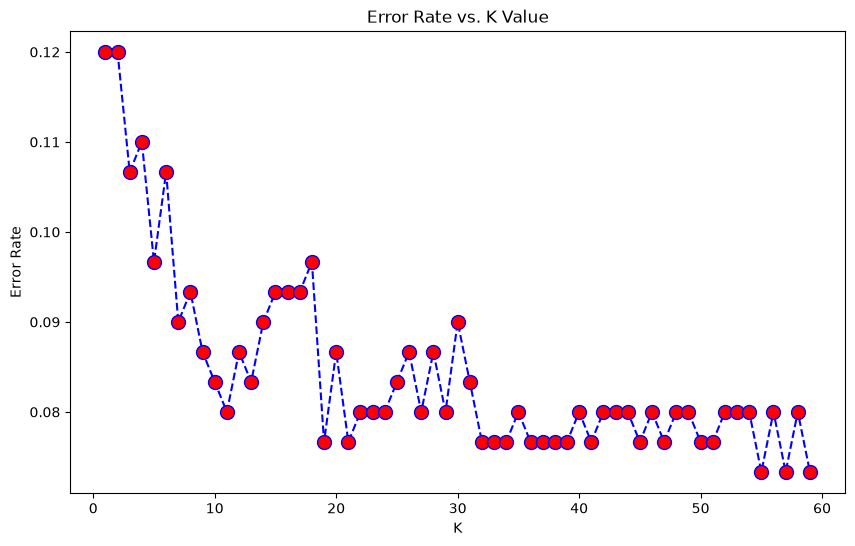

In [11]:
#將k=1~60的錯誤率製圖畫出。k=23之後，錯誤率就在5-6%之間震盪。
plt.figure(figsize=(10,6))
plt.plot(range(1,60),error_rate,color='blue',linestyle='dashed',marker='o',markerfacecolor='red',markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

In [12]:
#跟一開始k=1做比較
knn = KNeighborsClassifier(n_neighbors=1)

knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print('WITH k=1')
print('\n')
print(confusion_matrix(y_test,pred))
print('\n')
print(classification_report(y_test,pred))

WITH k=1


[[138  12]
 [ 24 126]]


              precision    recall  f1-score   support

           0       0.85      0.92      0.88       150
           1       0.91      0.84      0.88       150

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300



In [13]:
#選擇錯誤率最低的K=?????來看precision、recall、f1-score、support表現

# 找出錯誤率最低的 K 值
best_k = np.argmin(error_rate) + 1
print("Best K =", best_k)

# 使用最佳 K 重新建立模型
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

# 預測測試資料
pred = knn.predict(X_test)

# 顯示混淆矩陣
print(confusion_matrix(y_test, pred))

# 顯示分類評估報告
print(classification_report(y_test, pred))


Best K = 55
[[139  11]
 [ 11 139]]
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       150
           1       0.93      0.93      0.93       150

    accuracy                           0.93       300
   macro avg       0.93      0.93      0.93       300
weighted avg       0.93      0.93      0.93       300

